# 01 · Preprocessing — Zilionis 2019 NSCLC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, split the manifold into its transcriptional lobes, and fix a single house
orientation for every downstream UMAP. Zilionis et al. (2019) profiled non-small-cell lung
cancer by **inDrop** (a platform not yet in this atlas run — a portability test): 7 patients,
two histologies (**LUSC** p1/p2, **LUAD** p3–p7). Every tunable choice is *derived from this
dataset*, not inherited from the Puram anchor. Whether the gastrulation / somitogenesis /
neural-crest axis branches or is a single gradient is **derived in 02 from the signature
geography**, not assumed here, so both lobes are carried forward. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zilionis2019_Lung | category: Lung


### Load malignant compartment
Zilionis et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's malignancy call); the loader exposes it as `celltype`, taken directly
(per protocol: use the publication's calls). inDrop UMI counts are `normalize_total`- and
`log1p`-transformed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total inDrop UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zilionis2019_Lung
Done.
full atlas: (31179, 31797)
malignant: (3995, 31797) | samples: 7
expression: X max 3.11 (log1p of normalize_total inDrop UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we look for the largest **multiplicative** cliff in the sorted per-sample counts
(the natural separatrix between tumour-bearing samples and spillover). Here the argmax gap is a
**clean, dominant cliff**: 232→75 (ratio 3.09), and it is 1.84× the runner-up gap (391→232,
ratio 1.69) — above the dominant-cliff bar (1.5×) — and the small side (75 cells) sits well
below 2×the 100-cell floor. The clean-count-gap premise (C3) is therefore **met** (unlike the
Qian/Steele/Peng lung/PDAC runs where it was degenerate). We cut at the geometric mean of the
cliff (131), dropping only the single sub-100 sample (p2, 75 cells) as spillover and keeping
6/7.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'p1': np.int64(1078), 'p3': np.int64(799), 'p5': np.int64(790), 'p7': np.int64(630), 'p6': np.int64(391), 'p4': np.int64(232), 'p2': np.int64(75)}
gap ratios: ['1078->799:1.35', '799->790:1.01', '790->630:1.25', '630->391:1.61', '391->232:1.69', '232->75:3.09']
argmax gap 232->75 (ratio 3.09); top/second = 1.84; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 131
kept 6/7 samples (min per-sample = 232) -> 3920 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): the
fraction falls sharply from pre-Harmony (0.91) to theta=2 (0.64) to theta=5 (0.41) and then
flattens (theta=10 ≈ theta=5, within noise). NSCLC malignant cells are strongly patient-specific
(distinct CNVs / driver states) and this cohort mixes two histologies, so we take the strongest
integration on the plateau (theta=10) to suppress the batch effect without collapsing structure.
PC count (20) and UMAP spread (1.3) follow the 10x/inDrop precedents (Kürten / Qian / Sun / Lee /
Steele, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20]); sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing improves sharply to theta=5 then flattens; strongest integration for the strong patient/histology batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 248
same-sample neighbour fraction | pre-Harmony 0.907 | sweep {2: 0.636, 5: 0.413, 10: 0.397}
selected theta = 10 (mixing improves sharply to theta=5 then flattens; strongest integration for the strong patient/histology batch effect, without collapsing structure)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous manifold. Here the manifold is already a single component (0 cells removed).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Lobe split + confound tests (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's two density lobes. We test what
separates them: **not cell cycle** (both lobes low-cycling, 2.5% vs 7.7%; overall only 6.4% —
this is *not* the proliferative split seen in Kürten/Lin), **not histology** (both lobes carry
LUAD and LUSC), **not one patient** (both lobes contain all 6 samples). What differs is the
**developmental-module leaning** — one lobe is Gast-higher, the other pSom-higher — so the lobes
are the two ends of one developmental axis (confirmed in 02). We label them by that leaning and
carry both forward.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
hist = {'p1':'LUSC','p2':'LUSC','p3':'LUAD','p4':'LUAD','p5':'LUAD','p6':'LUAD','p7':'LUAD'}
adata.obs['histology'] = adata.obs['sample'].map(hist).astype('category')
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('lobe x histology (both mixed -> not a histology split):')
print(pd.crosstab(adata.obs['lobe'], adata.obs['histology']))

lobe sizes: {'1': 2881, '0': 1039}
overall cycling fraction: 0.064
cycling fraction per lobe: {'0': 0.025, '1': 0.077}
proliferation score per lobe: {'0': -0.025, '1': -0.01}
lobe x histology (both mixed -> not a histology split):
histology  LUAD  LUSC
lobe                 
0           840   199
1          2002   879


### Developmental modules + house orientation
Score the three embryonic signatures (Gast / pSom / Crest) against the shared **union** control
pool and graph-smooth them to read geography. Label each lobe by its smoothed Gast leaning
(origin side = Gast-high). The developmental axis is near-diagonal in the raw embedding, so every
trajectory panel is shown after a single **rigid rotation** to the house horizontal layout
(distance-preserving — *not* a re-embedding), derived **once here** and stored as `X_umap_lin`,
re-used unchanged by 02/03/04. Rotation angle = the manifold's axis of maximal variance; the
sign places the **developmental origin (Gast-high, the earliest programme) on the left** so
pseudotime runs left→right once fit in 02.

In [8]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Ssm = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Ssm = A @ Ssm
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = Ssm[:,j]
gast_lobe = adata.obs.groupby('lobe', observed=True)['Gast_sm'].mean().idxmax()
lab_map = {l: ('Gast-leaning' if l==gast_lobe else 'pSom-leaning') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('per-lobe smoothed module means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

origin_score = adata.obs['Gast_sm'].values - adata.obs['pSom_sm'].values   # Gast-high origin -> left
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), Gast-high origin pole on left; stored as X_umap_lin')

Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present
per-lobe smoothed module means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0     -0.0211   0.0436   -0.0191
1     -0.0012   0.0360   -0.0253
compartments: {'Gast-leaning': 2881, 'pSom-leaning': 1039}
manifold aspect (max/min std): 1.07
house orientation: rigid rotation -20.1deg (distances preserved), Gast-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient / per-histology islands) on one continuous manifold. The
read is made on the regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a
scalar alone. Both lobes contain all 6 samples and both histologies, and the manifold is one
connected component (0 islands). **Gate 1 = GO.**

In [9]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print('per-lobe sample spread (all 6 samples present in each lobe):')
for lb in adata.obs['lobe'].cat.categories:
    sub = adata.obs[adata.obs['lobe']==lb]; print(f'  lobe {lb}: {sub["sample"].nunique()} samples, {sub["histology"].nunique()} histologies')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold (no per-patient/histology archipelago) -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.35 of 6 samples
per-lobe sample spread (all 6 samples present in each lobe):
  lobe 0: 6 samples, 2 histologies
  lobe 1: 6 samples, 2 histologies
Gate 1: samples intermix per-neighbourhood on one continuous manifold (no per-patient/histology archipelago) -> PASS


### Save processed data
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is h5ad-serializable; analysis-relevant columns preserved.

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase','source','disease','histology'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


### Sample-integration figure (deliverable)
House style `(3.5,1.5)` horizontal strip, `size=30`, on the house orientation (`X_umap_lin`). Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 3920


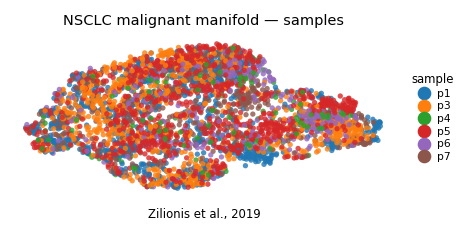

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('NSCLC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])